In [32]:
# Libraries
from datasets import load_dataset
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os
import fitz
from PIL import Image
from IPython.display import display
import random

In [3]:
#!pip install -U datasets huggingface_hub pyarrow pandas matplotlib seaborn pillow

## DocLayNet Exploration

In [4]:
# Load in DocLayNet
doc_data = load_dataset(
    "docling-project/DocLayNet-v1.2",
    revision="refs/convert/parquet"
)

Resolving data files:   0%|          | 0/72 [00:00<?, ?it/s]

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  519MB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

default/train/0001.parquet: reconstructing file:   0%|          |  0.00B /  520MB            

default/train/0001.parquet: downloading bytes:           |  0.00B            

default/train/0002.parquet: reconstructing file:   0%|          |  0.00B /  525MB            

... (165 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Loading dataset shards:   0%|          | 0/68 [00:00<?, ?it/s]

In [5]:
# Verifying data has loaded correctly
for split in doc_data.keys():

    print(f"\n{split.upper()}")
    print("Number of pages:", len(doc_data[split]))
    print("Columns:", doc_data[split].column_names)


TRAIN
Number of pages: 69375
Columns: ['image', 'bboxes', 'category_id', 'segmentation', 'area', 'pdf_cells', 'metadata', 'pdf', 'modalities']

VALIDATION
Number of pages: 6489
Columns: ['image', 'bboxes', 'category_id', 'segmentation', 'area', 'pdf_cells', 'metadata', 'pdf', 'modalities']

TEST
Number of pages: 4999
Columns: ['image', 'bboxes', 'category_id', 'segmentation', 'area', 'pdf_cells', 'metadata', 'pdf', 'modalities']


In [6]:
total_pages = sum(
    len(doc_data[split])
    for split in doc_data.keys()
)

print("Total pages:", total_pages)

Total pages: 80863


In [7]:
# Looking at features
print(doc_data["train"].features)

{'image': Image(mode=None, decode=True), 'bboxes': List(List(Value('float64'))), 'category_id': List(Value('int64')), 'segmentation': List(List(List(Value('float64')))), 'area': List(Value('float64')), 'pdf_cells': List(List({'bbox': List(Value('float64')), 'font': {'color': List(Value('int64')), 'name': Value('string'), 'size': Value('float64')}, 'text': Value('string')})), 'metadata': {'coco_height': Value('int64'), 'coco_width': Value('int64'), 'collection': Value('string'), 'doc_category': Value('string'), 'image_id': Value('int64'), 'num_pages': Value('int64'), 'original_filename': Value('string'), 'original_height': Value('float64'), 'original_width': Value('float64'), 'page_hash': Value('string'), 'page_no': Value('int64')}, 'pdf': Value('binary'), 'modalities': List(Value('string'))}


In [8]:
# Looking at first sample
sample = doc_data["train"][0]

for key, value in sample.items():

    if key == "image":
        print(key, value.size)

    elif key == "pdf":
        print(key, type(value))

    else:
        print(f"\n{key}:")
        print(str(value)[:500])

image (1025, 1025)

bboxes:
[[72.35294285130719, 55.47565740740731, 372.2156845996732, 20.452899744572278], [100.1946343137255, 117.51495402298849, 789.325354248366, 42.370593869731806], [100.1946343137255, 166.60499233716473, 787.606971895425, 56.115804597701185], [100.1946343137255, 229.44024137931035, 782.7989682189542, 56.115804597701185], [100.1946343137255, 292.27549042145586, 733.4930013071895, 42.37059386973192], [100.1946343137255, 341.3655287356321, 757.4533644607844, 28.62538314176254], [100.1946343137255, 500.4

category_id:
[6, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 5, 8, 9, 9]

segmentation:
[[[72.35294285130719, 55.47565740740731, 72.35294285130719, 75.92855715197959, 444.5686274509804, 75.92855715197959, 444.5686274509804, 55.47565740740731]], [[100.1946343137255, 117.51495402298849, 100.1946343137255, 159.8855478927203, 889.5199885620915, 159.8855478927203, 889.5199885620915, 117.51495402298849]], [[100.1946343137255, 166.60499233716473, 100.1946343137255, 222.7207969

In [13]:
# Look at layout/distribution
category_counts = Counter()

for split in doc_data.keys():

    for example in doc_data[split]:

        category_counts.update(
            example["category_id"]
        )

category_df = pd.DataFrame(
    category_counts.items(),
    columns=["Category ID", "Count"]
).sort_values("Count", ascending=False)

display(category_df)

,Category ID,Count
1,10,510377
6,4,185660
3,8,142884
2,5,70878
0,6,58022
5,7,45976
4,9,34733
10,3,25027
7,1,22524
8,2,6318


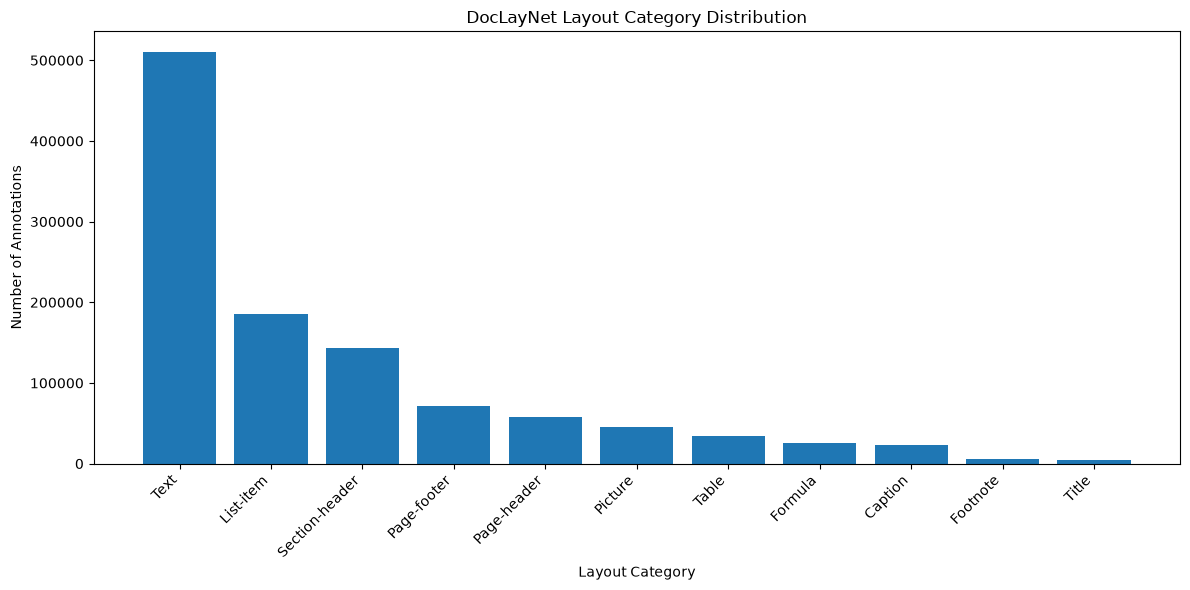

In [35]:
# Visualize distribution
category_names = {
    1: "Caption",
    2: "Footnote",
    3: "Formula",
    4: "List-item",
    5: "Page-footer",
    6: "Page-header",
    7: "Picture",
    8: "Section-header",
    9: "Table",
    10: "Text",
    11: "Title"
}

plt.figure(figsize=(12, 6))

plt.bar(
    category_df["Category ID"].map(category_names),
    category_df["Count"]
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Layout Category")
plt.ylabel("Number of Annotations")
plt.title("DocLayNet Layout Category Distribution")

plt.tight_layout()
plt.show()

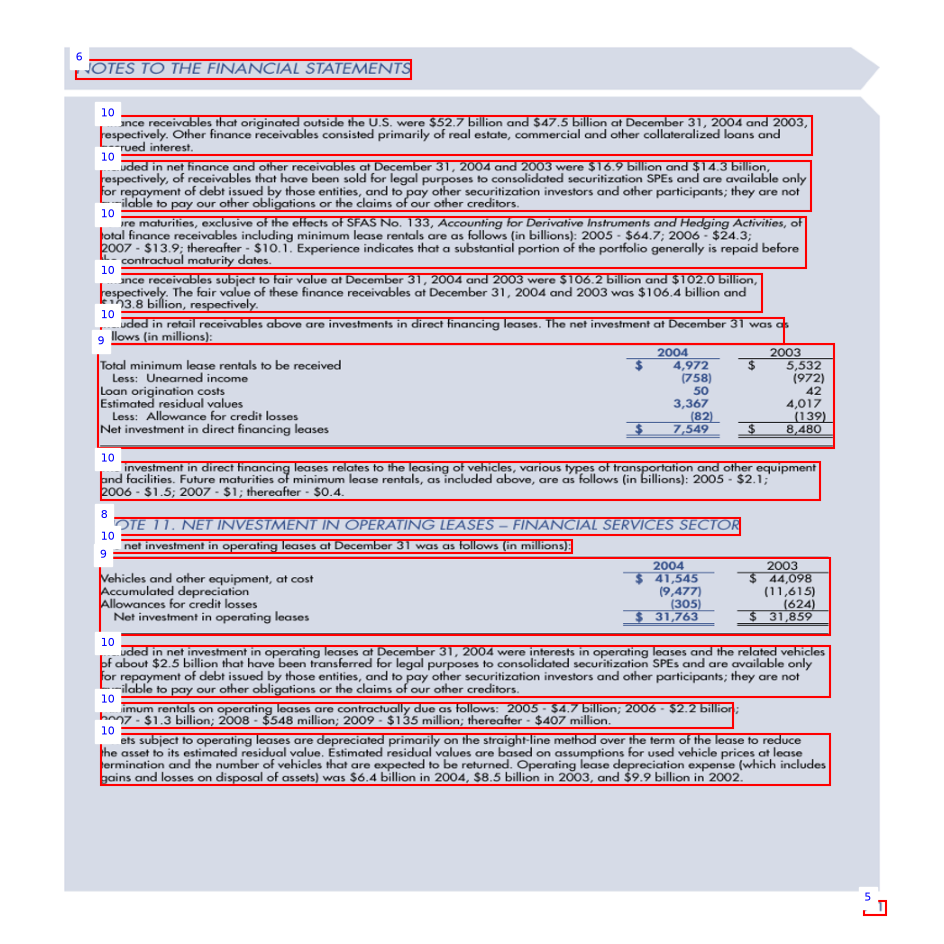

In [16]:
# Look at a doc page/bounding boxes
sample = doc_data["train"][0]

image = sample["image"].convert("RGB")

fig, ax = plt.subplots(figsize=(12, 12))

ax.imshow(image)

for bbox, category in zip(
    sample["bboxes"],
    sample["category_id"]
):

    x, y, width, height = bbox

    rect = patches.Rectangle(
        (x, y),
        width,
        height,
        linewidth=1.5,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        x,
        y,
        str(category),
        color="blue",
        fontsize=8,
        backgroundcolor="white"
    )

ax.axis("off")
plt.show()

## PDF Accessibility Benchmark (2025) Exploration

In [17]:
# Clone from github
!git clone https://github.com/Anukriti12/PDF-Accessibility-Benchmark.git

Cloning into 'PDF-Accessibility-Benchmark'...
remote: Enumerating objects: 1411, done.
remote: Counting objects: 100% (188/188), done.
remote: Compressing objects: 100% (117/117), done.
remote: Total 1411 (delta 76), reused 178 (delta 70), pack-reused 1223 (from 2)
Receiving objects: 100% (1411/1411), 280.68 MiB | 25.25 MiB/s, done.
Resolving deltas: 100% (552/552), done.
Updating files: 100% (2374/2374), done.


In [18]:
# Go through repository and find dataset
DATA_DIR = "/content/PDF-Accessibility-Benchmark"

for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:10]:
            print("  " * (level + 1) + file)

PDF-Accessibility-Benchmark/
  .DS_Store
  metadata.json
  directory.txt
  README.md
  LICENSE
  scripts/
    .DS_Store
    voiceover.json
  .git/
    HEAD
    config
    index
    packed-refs
    description
    branches/
    refs/
      remotes/
      heads/
        main
      tags/
    hooks/
      pre-commit.sample
      pre-receive.sample
      pre-rebase.sample
      prepare-commit-msg.sample
      fsmonitor-watchman.sample
      applypatch-msg.sample
      update.sample
      post-update.sample
      pre-push.sample
      sendemail-validate.sample
    objects/
      pack/
        pack-6040e217909cfbc130f728fe099857d1d52decf9.rev
        pack-6040e217909cfbc130f728fe099857d1d52decf9.pack
        pack-6040e217909cfbc130f728fe099857d1d52decf9.idx
      info/
    logs/
      HEAD
      refs/
    info/
      exclude
  data/
    .DS_Store
    dataset.json
    processed/
      .DS_Store
      logical_reading_order/
        .DS_Store
      fonts_readability/
        .DS_Store
      alt_

In [30]:
# Checking for criteria labels
DATA_DIR = "/content/PDF-Accessibility-Benchmark"

criteria = [
    "alt_text_quality",
    "color_contrast",
    "fonts_readability",
    "functional_hyperlinks",
    "logical_reading_order",
    "semantic_tagging",
    "table_structure"
]

labels = ["passed", "failed", "not_present", "cannot_tell"]

records = []

for criterion in criteria:
    for label in labels:
        folder = os.path.join(DATA_DIR, "inputs", criterion, label)

        if os.path.exists(folder):
            pdf_count = sum(
                1 for root, dirs, files in os.walk(folder)
                for file in files
                if file.lower().endswith(".pdf")
            )
        else:
            pdf_count = 0

        records.append({
            "Criterion": criterion,
            "Label": label,
            "Count": pdf_count
        })

complete_benchmark_df = pd.DataFrame(records)

display(
    complete_benchmark_df.pivot(
        index="Criterion",
        columns="Label",
        values="Count"
    ).fillna(0).astype(int)
)

Label,cannot_tell,failed,not_present,passed
Criterion,,,,
alt_text_quality,7,7,7,7
color_contrast,20,20,0,20
fonts_readability,6,6,0,6
functional_hyperlinks,22,22,22,22
logical_reading_order,21,21,0,21
semantic_tagging,0,0,4,5
table_structure,27,27,27,27


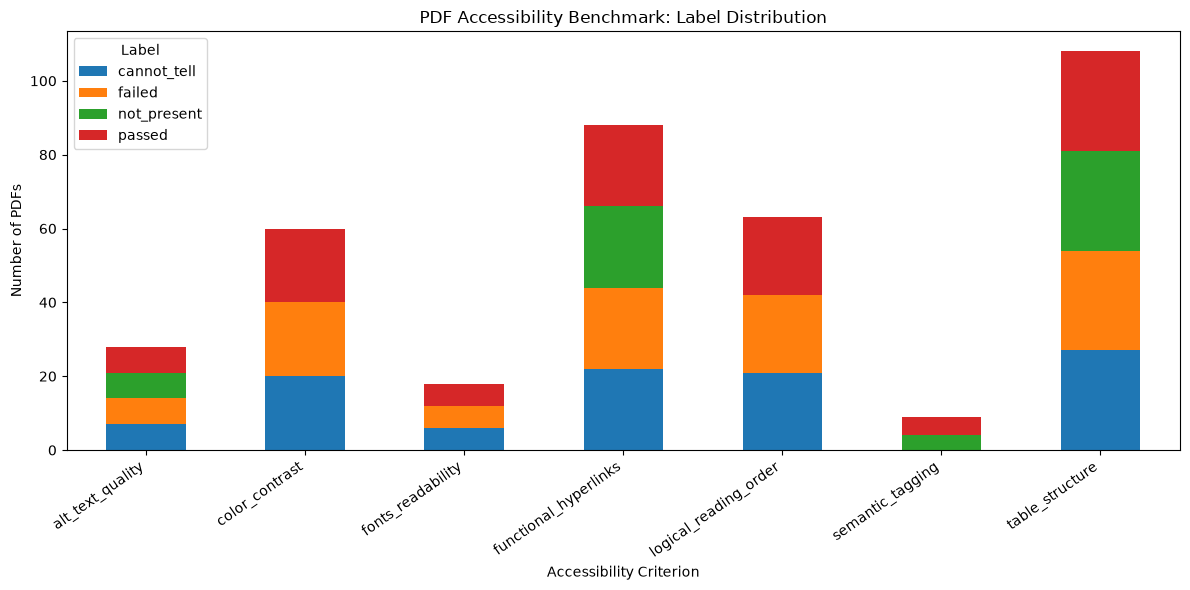

In [31]:
# Visualizing actual distribution
plot_df = complete_benchmark_df.pivot(
    index="Criterion",
    columns="Label",
    values="Count"
).fillna(0)

plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("PDF Accessibility Benchmark: Label Distribution")
plt.xlabel("Accessibility Criterion")
plt.ylabel("Number of PDFs")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Label")
plt.tight_layout()
plt.show()

Selected PDF: W2929611936_1.pdf
Criterion: alt_text_quality
Label: failed
File size: 214.50 KB

--- PDF METADATA ---
{'format': 'PDF 1.7', 'title': 'Neutrino Emission from the Direction of the Blazar TXS 0506+056 Prior to the IceCube-170922A Alert', 'author': 'IceCube Collaboration and Karen Andeen', 'subject': '', 'keywords': '', 'creator': 'Appligent pdfHarmony 2.0', 'producer': 'Prince 9.0 rev 5 (www.princexml.com)', 'creationDate': 'D:20250209010036Z', 'modDate': 'D:20250209010036Z', 'trapped': '', 'encryption': None}

Number of pages: 1

--- EXTRACTED TEXT (FIRST PAGE) ---
 
Fig. 2 Time-independent weight of individual events during the IC86b period. 
Each vertical line represents an event observed at the time indicated by calendar year (top) or MJD (bottom). Overlapping 
lines are shifted by 1 to 2 days for visibility. The height of each line indicates the event weight: the product of the event’s 
spatial term and energy term in the unbinned likelihood analysis evaluated at the l

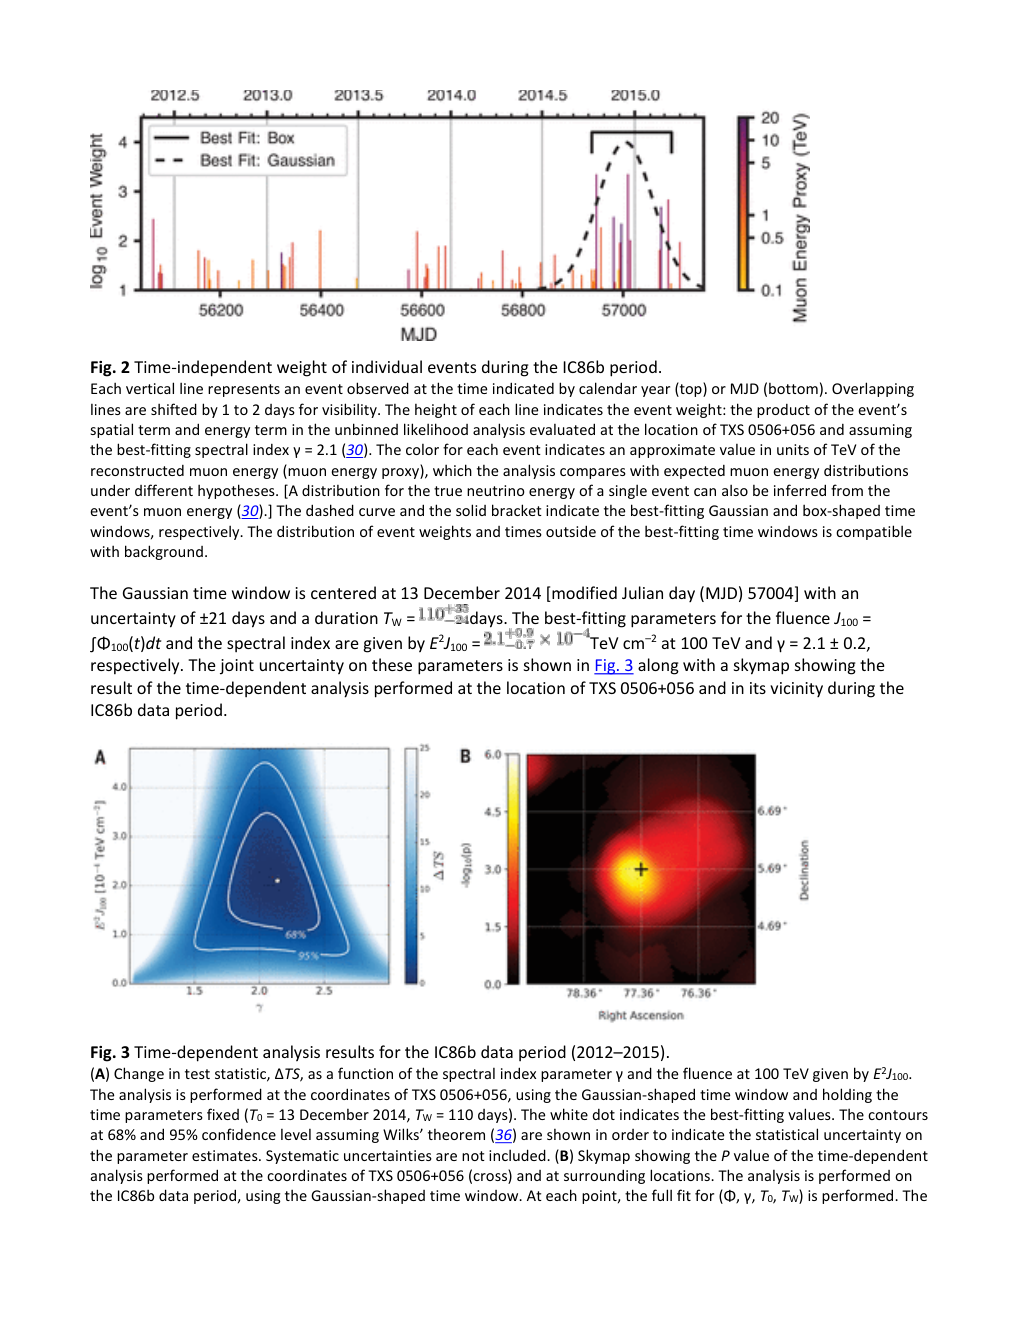

In [33]:
# Analyzing a sample
DATA_DIR = "/content/PDF-Accessibility-Benchmark"

# Choose which type of example to inspect
# Can change according to previous labels listed
criterion = "alt_text_quality"
label = "failed"

# Find PDFs, including those in nested folders
folder = os.path.join(DATA_DIR, "inputs", criterion, label)

pdf_paths = []

for root, dirs, files in os.walk(folder):
    for file in files:
        if file.lower().endswith(".pdf"):
            pdf_paths.append(os.path.join(root, file))

if not pdf_paths:
    print(f"No PDFs found for {criterion} / {label}")
else:
    # Select a reproducible random sample
    random.seed(42)
    sample_path = random.choice(pdf_paths)

    print("Selected PDF:", os.path.basename(sample_path))
    print("Criterion:", criterion)
    print("Label:", label)
    print(f"File size: {os.path.getsize(sample_path) / 1024:.2f} KB")

    # Open PDF
    doc = fitz.open(sample_path)

    print("\n--- PDF METADATA ---")
    print(doc.metadata)

    print("\nNumber of pages:", len(doc))

    # Extract first page text
    first_page = doc[0]
    extracted_text = first_page.get_text("text")

    print("\n--- EXTRACTED TEXT (FIRST PAGE) ---")
    print(extracted_text[:3000] if extracted_text.strip()
          else "No selectable text found on the first page.")

    # Render first page as an image
    pix = first_page.get_pixmap(dpi=120)
    page_image = Image.frombytes(
        "RGB",
        [pix.width, pix.height],
        pix.samples
    )

    print("\n--- FIRST PAGE PREVIEW ---")
    display(page_image)

    doc.close()